# 06 · Bayesian hyperparameter optimisation of Random Forest

**Input:** `data/features/*.parquet` (notebook 03), the untuned results of notebook 04 and the tuned LightGBM of notebook 05.
**Output:** `outputs/tuning_rf/` (trials, best parameters, search space, comparisons, figures, `TUNING_REPORT_RF.md`) and
`models/RandomForest_tuned.joblib`. The untuned `models/RandomForest.joblib` is left as it is.

**Why tune Random Forest too:** in notebook 04, Random Forest was the most accurate model (CV Top-1 0.8871, student_test
0.9001). LightGBM was within a few tenths of a percentage point, and was tuned first because it trains about 3× faster.
Tuning both gives a fair basis for choosing the final model.

**Protocol:** identical to notebook 05 (code in `src/pathsnap/tuning.py`, metrics from `src/pathsnap/training.py`).
* Same features, training rows (`label_reliable & ~exclude_trip`) and the **same 5 GroupKFold folds** (seed 42).
* **Sampler:** Optuna TPE (seed 42). **Pruner:** MedianPruner (from the first fold, after 5 finished trials).
* **Objective:** mean CV **observation-level Top-1 accuracy** (all labelled fixes), the same as for LightGBM.
* The untuned Random Forest is queued as **trial 0**.
* **student_test is not used during the search.** It is scored once, after the best configuration is refit.

In [1]:
import json, sys, time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from sklearn.model_selection import GroupKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from pathsnap import training as T, tuning as TU
from pathsnap.cleaning import PROCESSED_ROOT

OUT, MODELS = ROOT / "outputs" / "tuning_rf", ROOT / "models"
FIG = OUT / "figures"
for d in (OUT, FIG):
    d.mkdir(parents=True, exist_ok=True)

train = pd.read_parquet(ROOT / "data" / "features" / "train.parquet")
test = pd.read_parquet(ROOT / "data" / "features" / "student_test.parquet")
train_fx = pd.read_parquet(ROOT / "data" / "features" / "train_fixes.parquet")
test_fx = pd.read_parquet(ROOT / "data" / "features" / "student_test_fixes.parquet")

def load_arcs(part):
    out = {}
    for d in (PROCESSED_ROOT / part).iterdir():
        a = pd.read_csv(d / "arcs.csv.gz", usecols=["from_node", "to_node"])
        out[d.name] = (a.from_node.to_numpy(), a.to_node.to_numpy())
    return out
arcs = {**load_arcs("train"), **load_arcs("student_test")}

# exactly the folds of notebooks 04 and 05
folds = list(GroupKFold(n_splits=T.N_FOLDS, shuffle=True, random_state=T.SEED).split(train, groups=train.trip_id.to_numpy()))
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#d9d8d2", "grid.linewidth": 0.6, "figure.dpi": 110})
print(f"optuna {optuna.__version__}; {len(train):,} train rows, {T.training_mask(train).sum():,} usable; {len(folds)} folds")

optuna 5.1.0; 1,530,256 train rows, 1,430,632 usable; 5 folds


## 1. Search space
| parameter | range | why |
|---|---|---|
| `n_estimators` | 50–250 (step 25) | number of trees; more trees mainly reduce variance, then flatten out |
| `max_features` | 0.1–0.4 (share of the 27 features tried at each split) | lower = more diverse trees; the untuned `sqrt` is 5 features (0.19) |
| `min_samples_leaf` | 5–200 (log) | minimum rows per leaf; larger = smoother trees and better-behaved probabilities |
| `max_samples` | 0.1–0.35 (share of rows per bootstrap sample) | rows each tree sees; also the main driver of training time |
| `max_depth` | None, 10, 15, 20, 30 | optional cap on tree depth |
| `criterion` | gini, entropy | split quality measure |

**Time budget:** a timing test showed one fold at 250 trees / 50 % of features / 40 % of rows takes about 4 min (a full
trial about 20 min), against 41 s for the untuned forest. So `max_features` and `max_samples` are capped at 0.4 and 0.35,
which keeps the search within about 75 minutes. The untuned configuration sits inside every range.
`class_weight` is not searched, because re-weighting the classes distorts the probabilities that the HMM step will use.

In [2]:
(OUT / "search_space.json").write_text(json.dumps({"space": TU.RF_SEARCH_SPACE, "fixed": TU.RF_FIXED,
    "baseline_trial0": TU.RF_BASELINE, "objective": "maximise mean CV Top-1 (all labelled fixes), 5 GroupKFold folds",
    "sampler": "TPESampler(seed=42)", "pruner": f"MedianPruner(n_startup_trials={TU.PRUNER_STARTUP_TRIALS}, n_warmup_steps=0)",
    "n_trials": TU.RF_N_TRIALS, "timeout_s": TU.RF_TIMEOUT_S}, indent=1, default=str), encoding="utf-8")
pd.DataFrame(TU.RF_SEARCH_SPACE).T

,type,low,high,step,log,choices
n_estimators,int,50,250,25,NaN,NaN
max_features,float,0.1,0.4,NaN,NaN,NaN
min_samples_leaf,int,5,200,NaN,True,NaN
max_samples,float,0.1,0.35,NaN,NaN,NaN
max_depth,categorical,NaN,NaN,NaN,NaN,"[None, 10, 15, 20, 30]"
criterion,categorical,NaN,NaN,NaN,NaN,"[gini, entropy]"


## 2. Run the search
At most `RF_N_TRIALS = 40` trials or 75 minutes, whichever comes first; the actual numbers are reported below. The study is
written to `outputs/tuning_rf/study.db` (SQLite) as it runs, so a crash does not lose finished trials.

In [3]:
db = OUT / "study.db"
db.unlink(missing_ok=True)                               # fresh study on every full run
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = TU.make_study(storage=f"sqlite:///{db.as_posix()}", name="random_forest_top1")
study.enqueue_trial(TU.RF_BASELINE)                      # trial 0 = untuned configuration

def progress(st, tr):
    best = st.best_value if any(t.state == optuna.trial.TrialState.COMPLETE for t in st.trials) else float("nan")
    val = f"{tr.value:.4f}" if tr.value is not None else "  -   "
    print(f"trial {tr.number:3d} {tr.state.name:8s} top1 {val}  best {best:.4f}  "
          f"({(tr.datetime_complete - tr.datetime_start).total_seconds():.0f}s)", flush=True)

t0 = time.perf_counter()
study.optimize(TU.make_objective(train, train_fx, folds, arcs, space=TU.RF_SEARCH_SPACE, build=TU.rf_spec),
               n_trials=TU.RF_N_TRIALS, timeout=TU.RF_TIMEOUT_S, callbacks=[progress], gc_after_trial=True)
search_s = time.perf_counter() - t0

trial   0 COMPLETE top1 0.8871  best 0.8871  (221s)


trial   1 COMPLETE top1 0.8847  best 0.8871  (275s)


trial   2 COMPLETE top1 0.8865  best 0.8871  (304s)


trial   3 COMPLETE top1 0.8872  best 0.8872  (146s)


trial   4 COMPLETE top1 0.8853  best 0.8872  (333s)


trial   5 PRUNED   top1 0.8456  best 0.8872  (35s)


... (27 outputs left out)

trial  33 PRUNED   top1 0.8517  best 0.8894  (38s)


trial  34 COMPLETE top1 0.8885  best 0.8894  (166s)


trial  35 PRUNED   top1 0.8506  best 0.8894  (37s)


trial  36 COMPLETE top1 0.8889  best 0.8894  (159s)


In [4]:
states = pd.Series([t.state.name for t in study.trials]).value_counts()
summary = {"trials_total": len(study.trials), "complete": int(states.get("COMPLETE", 0)),
           "pruned": int(states.get("PRUNED", 0)), "failed": int(states.get("FAIL", 0)),
           "wall_clock_min": round(search_s / 60, 1), "best_trial": study.best_trial.number,
           "best_cv_top1": round(study.best_value, 4)}
summary

{'trials_total': 37,
 'complete': 23,
 'pruned': 14,
 'failed': 0,
 'wall_clock_min': 76.4,
 'best_trial': 26,
 'best_cv_top1': 0.8894}

In [5]:
df = study.trials_dataframe(attrs=("number", "state", "value", "params", "user_attrs", "duration"))
df.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in df.columns]
df["duration_s"] = df.pop("duration").dt.total_seconds()
# a pruned trial's `value` is only its running mean when it was stopped (often after the easy first fold),
# so it is NOT comparable with completed trials: keep it separately and blank `value` for pruned trials
df["folds_completed"] = [sum(f"fold{k}_all_top1" in t.user_attrs for k in range(T.N_FOLDS)) for t in study.trials]
df["running_mean_when_stopped"] = df["value"].where(df["state"] == "PRUNED")
df["value"] = df["value"].where(df["state"] == "COMPLETE")
df.to_csv(OUT / "trials.csv", index=False)
best = study.best_trial
best_params = {**best.params, **TU.RF_FIXED}
(OUT / "best_params.json").write_text(json.dumps({"trial": best.number, "cv_top1": best.value,
                                                  "params": best_params, **summary}, indent=1), encoding="utf-8")
cols = ["number", "state", "value", "folds_completed", "cv_all_macro_f1_mean", "cv_all_logloss_mean", "n_estimators",
        "max_features", "min_samples_leaf", "max_samples", "max_depth", "criterion", "duration_s"]
df.sort_values("value", ascending=False)[cols].head(10).round(4)

,number,state,value,folds_completed,cv_all_macro_f1_mean,cv_all_logloss_mean,n_estimators,max_features,min_samples_leaf,max_samples,max_depth,criterion,duration_s
26,26,COMPLETE,0.8894,5,0.9356,0.0714,175,0.1212,5,0.3439,15.0,entropy,182.8161
28,28,COMPLETE,0.8894,5,0.9358,0.0690,225,0.1792,5,0.2476,15.0,entropy,219.4342
30,30,COMPLETE,0.8890,5,0.9353,0.0719,150,0.1464,7,0.3390,15.0,entropy,155.4994
36,36,COMPLETE,0.8889,5,0.9352,0.0721,225,0.1342,7,0.2105,15.0,entropy,159.4205
25,25,COMPLETE,0.8887,5,0.9352,0.0724,175,0.1249,10,0.3449,15.0,entropy,182.8753
14,14,COMPLETE,0.8887,5,0.9348,0.0710,175,0.1380,6,0.2270,20.0,entropy,136.2129
32,32,COMPLETE,0.8887,5,0.9352,0.0723,125,0.1413,7,0.2894,15.0,entropy,116.9127
34,34,COMPLETE,0.8885,5,0.9346,0.0728,175,0.1266,15,0.3039,15.0,entropy,165.8546
24,24,COMPLETE,0.8883,5,0.9350,0.0709,200,0.1238,8,0.3132,20.0,entropy,197.9165
16,16,COMPLETE,0.8882,5,0.9344,0.0724,100,0.1318,10,0.2323,20.0,entropy,82.6250


### Sanity check: trial 0 against notebook 04
Trial 0 is the untuned Random Forest (`max_features=0.1925` is the same 5 features as `sqrt`), re-run on the same folds.
Its per-fold Top-1 should match notebook 04.

In [6]:
nb04 = pd.read_csv(ROOT / "outputs" / "models" / "per_fold.csv")
nb04_rf = nb04[nb04.model == "RandomForest"].sort_values("fold")
t0_row = df[df.number == 0].iloc[0]
pd.DataFrame({"notebook 04": nb04_rf.all_top1.to_numpy(),
              "trial 0": [t0_row[f"fold{k}_all_top1"] for k in range(T.N_FOLDS)]},
             index=[f"fold {k}" for k in range(T.N_FOLDS)]).round(5)

,notebook 04,trial 0
fold 0,0.84863,0.84863
fold 1,0.91899,0.91899
fold 2,0.88320,0.88320
fold 3,0.93090,0.93090
fold 4,0.85366,0.85366


## 3. Search figures

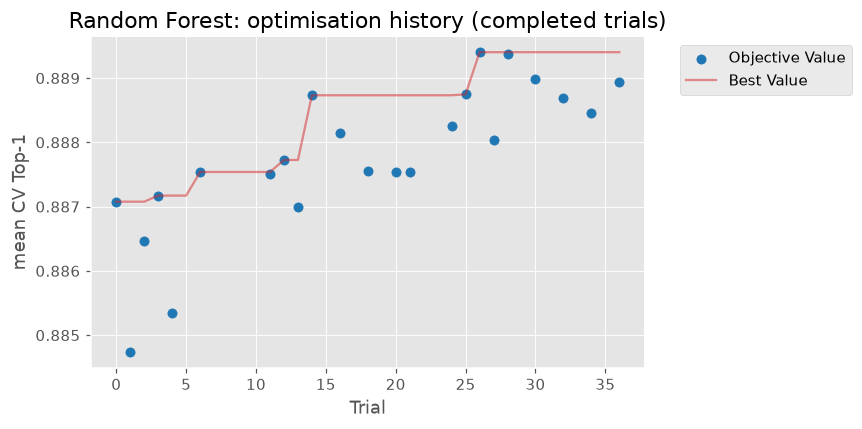

In [7]:
from optuna.visualization import matplotlib as ovm
import warnings; warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

ax = ovm.plot_optimization_history(study)
ax.set_title("Random Forest: optimisation history (completed trials)"); ax.set_ylabel("mean CV Top-1")
ax.figure.set_size_inches(8, 4); ax.figure.tight_layout(); ax.figure.savefig(FIG / "optimisation_history.png"); plt.show()

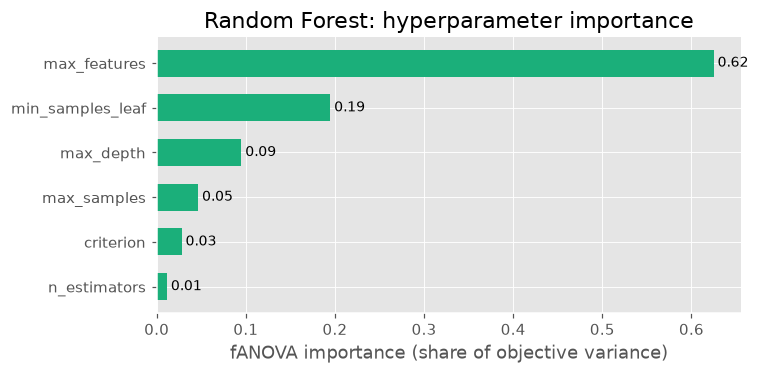

['max_features', 'min_samples_leaf']

In [8]:
imp = optuna.importance.get_param_importances(study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=T.SEED))
imp = pd.Series(imp).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(imp.index, imp.values, color="#1baf7a", height=0.6)
for y, v in enumerate(imp.values): ax.text(v, y, f" {v:.2f}", va="center", fontsize=9)
ax.set_xlabel("fANOVA importance (share of objective variance)"); ax.set_title("Random Forest: hyperparameter importance")
fig.tight_layout(); fig.savefig(FIG / "param_importance.png"); plt.show()
top2 = list(imp.sort_values(ascending=False).index[:2]); top2

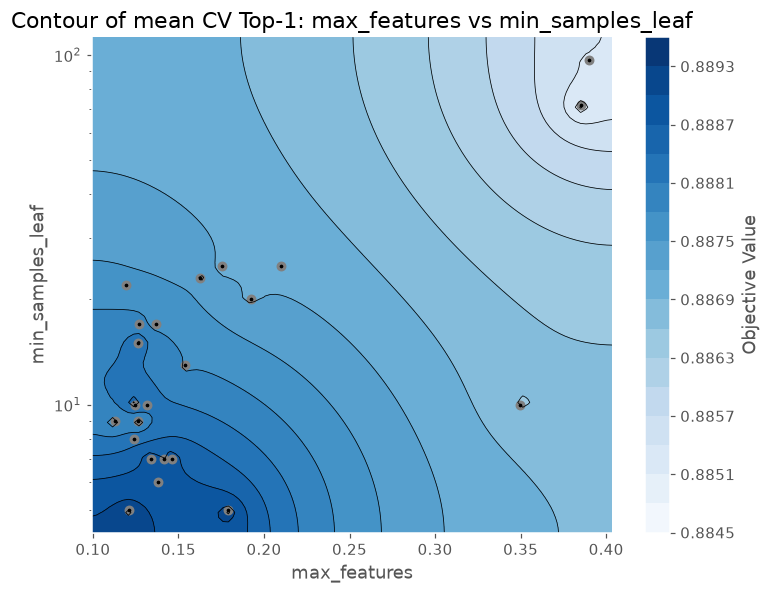

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_5740\798338064.py:5: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig = np.atleast_1d(axes)[0].figure; fig.set_size_inches(10, 4); fig.tight_layout()


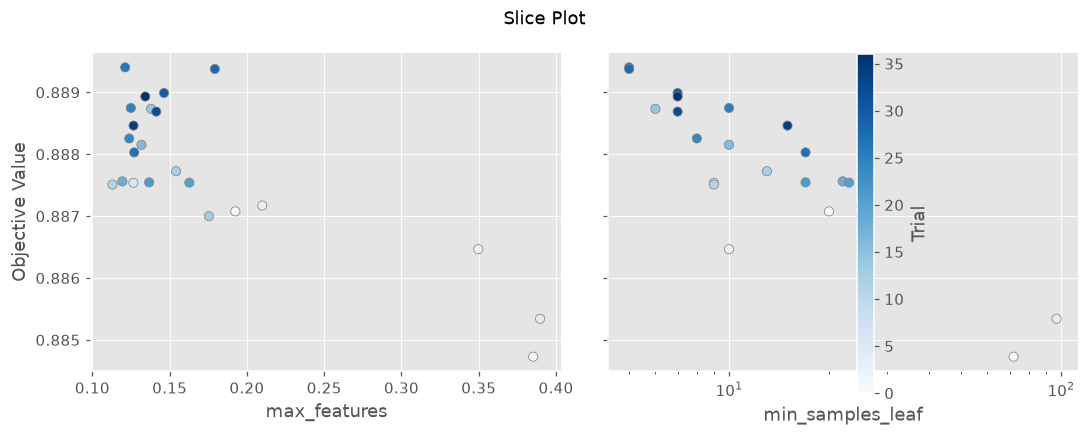

In [9]:
ax = ovm.plot_contour(study, params=top2)
ax.figure.set_size_inches(7, 5.5); ax.set_title(f"Contour of mean CV Top-1: {top2[0]} vs {top2[1]}")
ax.figure.tight_layout(); ax.figure.savefig(FIG / "contour_top2.png"); plt.show()
axes = ovm.plot_slice(study, params=top2)
fig = np.atleast_1d(axes)[0].figure; fig.set_size_inches(10, 4); fig.tight_layout()
fig.savefig(FIG / "slice_top2.png"); plt.show()

## 4. Refit the best configuration on all usable train trips, then score student_test once

In [10]:
spec = TU.rf_spec(best.params)
model, fit_s, _ = T.fit_model(spec, train[T.training_mask(train)])
p, pred_s = T.predict(model, test)
m = T.evaluate(test, test_fx, p, arcs)
path = MODELS / "RandomForest_tuned.joblib"
joblib.dump(model, path, compress=3)
(OUT / "tuned_student_test_cm.json").write_text(json.dumps({"all": m["all_cm"], "reliable": m["reliable_cm"]}), encoding="utf-8")
print(f"tuned RF: student_test Top-1 {m['all_top1']:.4f}, macro F1 {m['all_macro_f1']:.4f}, log loss {m['all_logloss']:.4f}, "
      f"fit {fit_s:.0f}s, file {path.stat().st_size / 1e6:.1f} MB")

tuned RF: student_test Top-1 0.8992, macro F1 0.9399, log loss 0.0611, fit 43s, file 22.8 MB


### Inference time: all four models re-timed in this session
Timings taken in different notebooks are not comparable, because machine load differs. So the untuned and tuned versions
of both models are timed here, back to back: the median of 3 `predict_proba` runs over all student_test candidate rows.

In [11]:
def time_model(mdl, reps=3):
    ts = [T.predict(mdl, test)[1] for _ in range(reps)]
    return 1e6 * float(np.median(ts)) / len(test_fx)
timing = {name: time_model(joblib.load(MODELS / f"{name}.joblib"))
          for name in ["LightGBM", "LightGBM_tuned", "RandomForest", "RandomForest_tuned"]}
pd.Series(timing, name="ms per 1,000 fixes").round(1).to_frame()

,"ms per 1,000 fixes"
LightGBM,39.1
LightGBM_tuned,50.0
RandomForest,16.2
RandomForest_tuned,17.8


## 5. Comparison: Random Forest and LightGBM, untuned and tuned
Untuned numbers come unchanged from notebook 04 (`outputs/models/`) and tuned LightGBM from notebook 05
(`outputs/tuning/`). CV numbers are always on the same 5 folds. Inference times are from the cell above, measured in this session.

In [12]:
mc = pd.read_csv(ROOT / "outputs" / "models" / "model_comparison.csv").set_index("model")
pf = nb04.groupby("model")
def from_nb04(name):
    g = pf.get_group(name); r = mc.loc[name]
    return {"CV macro F1": g.all_macro_f1.mean(), "CV Top-1": g.all_top1.mean(), "CV Top-1 std": g.all_top1.std(),
            "CV log loss": g.all_logloss.mean(), "ST Top-1": r["ST Top-1 (all)"],
            "ST Top-1 (reliable)": r["ST Top-1 (reliable)"], "ST macro F1": r["ST macro F1 (all)"],
            "ST log loss": r["ST log loss (all)"], "ST route continuity": r["ST route continuity"],
            "train time (s)": r["train time (s)"], "model file (MB)": r["model file (MB)"]}
def from_trial(ua, st, fit, mb):
    return {"CV macro F1": ua["cv_all_macro_f1_mean"], "CV Top-1": ua["cv_all_top1_mean"], "CV Top-1 std": ua["cv_all_top1_std"],
            "CV log loss": ua["cv_all_logloss_mean"], "ST Top-1": st["all_top1"], "ST Top-1 (reliable)": st["reliable_top1"],
            "ST macro F1": st["all_macro_f1"], "ST log loss": st["all_logloss"], "ST route continuity": st["route_continuity"],
            "train time (s)": fit, "model file (MB)": mb}

lgb_t = pd.read_csv(ROOT / "outputs" / "tuning" / "tuned_vs_untuned.csv", index_col=0).loc["LightGBM tuned"]
lgb_best = json.loads((ROOT / "outputs" / "tuning" / "best_params.json").read_text())
lgb_trials = pd.read_csv(ROOT / "outputs" / "tuning" / "trials.csv").set_index("number")
lgb_ua = lgb_trials.loc[lgb_best["trial"]]
comp = pd.DataFrame({
    "RandomForest untuned": from_nb04("RandomForest"),
    "RandomForest tuned": from_trial(best.user_attrs, m, fit_s, path.stat().st_size / 1e6),
    "LightGBM untuned": from_nb04("LightGBM"),
    "LightGBM tuned": {**{k: lgb_t[k] for k in ["CV macro F1", "CV Top-1", "CV Top-1 std", "CV log loss", "ST Top-1",
                                                 "ST Top-1 (reliable)", "ST macro F1", "ST log loss", "ST route continuity",
                                                 "train time (s)", "model file (MB)"]}},
}).T
comp["inference ms / 1k fixes (this session)"] = [timing["RandomForest"], timing["RandomForest_tuned"],
                                                  timing["LightGBM"], timing["LightGBM_tuned"]]
comp.to_csv(OUT / "rf_lgbm_tuned_vs_untuned.csv")
comp.astype(float).round(4).T

,RandomForest untuned,RandomForest tuned,LightGBM untuned,LightGBM tuned
CV macro F1,0.9342,0.9356,0.9328,0.9362
CV Top-1,0.8871,0.8894,0.8851,0.8900
CV Top-1 std,0.0372,0.0365,0.0379,0.0384
CV log loss,0.0695,0.0714,0.0703,0.0681
ST Top-1,0.9001,0.8992,0.8943,0.8961
ST Top-1 (reliable),0.9012,0.9003,0.8955,0.8972
ST macro F1,0.9395,0.9399,0.9352,0.9384
ST log loss,0.0589,0.0611,0.0574,0.0577
ST route continuity,0.9556,0.9550,0.9595,0.9597
train time (s),93.1000,43.4189,29.0000,15.8134


In [13]:
# per fold: is the CV gain consistent, or one lucky fold?
paired = pd.DataFrame({"RF untuned": nb04_rf.all_top1.to_numpy(),
                       "RF tuned": [best.user_attrs[f"fold{k}_all_top1"] for k in range(T.N_FOLDS)],
                       "LightGBM untuned": nb04[nb04.model == "LightGBM"].sort_values("fold").all_top1.to_numpy(),
                       "LightGBM tuned": [lgb_ua[f"fold{k}_all_top1"] for k in range(T.N_FOLDS)]},
                      index=[f"fold {k}" for k in range(T.N_FOLDS)])
paired["RF tuned - RF untuned (pp)"] = 100 * (paired["RF tuned"] - paired["RF untuned"])
paired["RF tuned - LGBM tuned (pp)"] = 100 * (paired["RF tuned"] - paired["LightGBM tuned"])
paired.to_csv(OUT / "per_fold_top1.csv")
paired.round(4)

,RF untuned,RF tuned,LightGBM untuned,LightGBM tuned,RF tuned - RF untuned (pp),RF tuned - LGBM tuned (pp)
fold 0,0.8486,0.8544,0.8474,0.8515,0.5738,0.2818
fold 1,0.9190,0.9232,0.9178,0.9274,0.4260,-0.4184
fold 2,0.8832,0.8849,0.8782,0.8846,0.1703,0.0335
fold 3,0.9309,0.9304,0.9307,0.9319,-0.0490,-0.1469
fold 4,0.8537,0.8541,0.8515,0.8548,0.0419,-0.0710


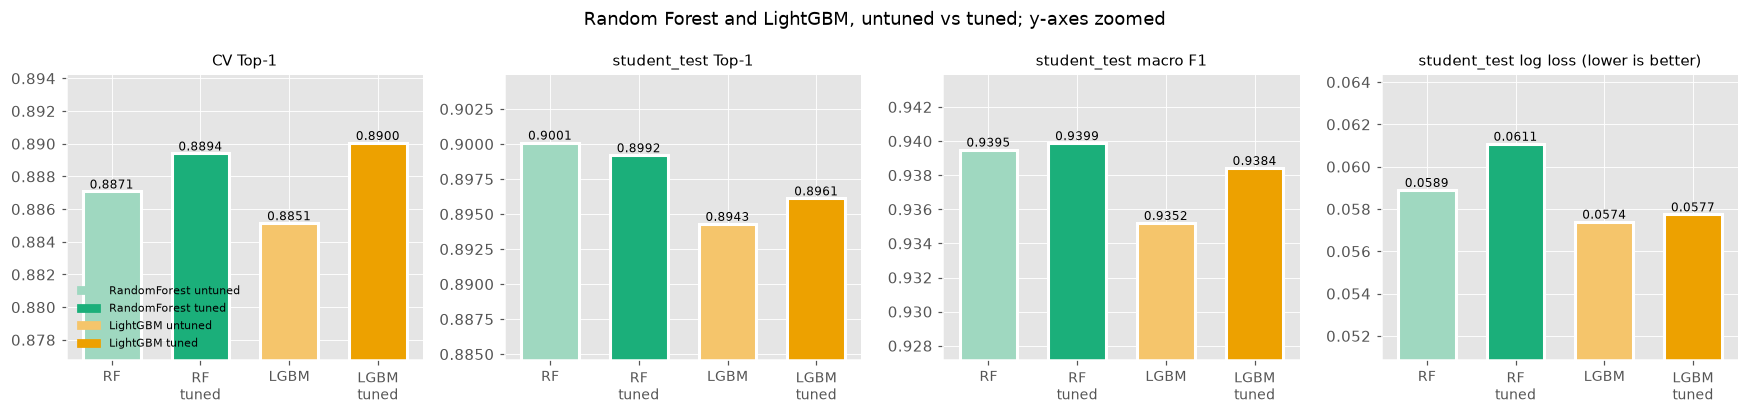

In [14]:
show = [("CV Top-1", "CV Top-1"), ("ST Top-1", "student_test Top-1"), ("ST macro F1", "student_test macro F1"),
        ("ST log loss", "student_test log loss (lower is better)")]
names = list(comp.index)
colors = ["#9fd8c0", "#1baf7a", "#f5c56b", "#eda100"]          # light = untuned, dark = tuned; green RF, yellow LightGBM
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (col, title) in zip(axes, show):
    v = comp[col].astype(float).values
    ax.bar(range(4), v, 0.65, color=colors, edgecolor="white", linewidth=2)
    for i, x in enumerate(v):
        ax.text(i, x, f"{x:.4f}", ha="center", va="bottom", fontsize=8)
    pad = (v.max() - v.min()) * 1.5 + 1e-3
    ax.set_ylim(v.min() - pad, v.max() + pad / 2)
    ax.set_xticks(range(4), ["RF", "RF\ntuned", "LGBM", "LGBM\ntuned"], fontsize=9); ax.set_title(title, fontsize=10)
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors], labels=names, frameon=False,
               fontsize=7.5, loc="lower left")
fig.suptitle("Random Forest and LightGBM, untuned vs tuned; y-axes zoomed")
fig.tight_layout(); fig.savefig(FIG / "rf_lgbm_tuned_vs_untuned.png"); plt.show()

## 6. Write `TUNING_REPORT_RF.md`

In [15]:
c = comp.astype(float)
d_cv = 100 * (c.loc["RandomForest tuned", "CV Top-1"] - c.loc["RandomForest untuned", "CV Top-1"])
d_st = 100 * (c.loc["RandomForest tuned", "ST Top-1"] - c.loc["RandomForest untuned", "ST Top-1"])
folds_up = int((paired["RF tuned - RF untuned (pp)"] > 0).sum())
bp = pd.Series(best.params).to_frame("best value")
bp["untuned value"] = pd.Series(TU.RF_BASELINE)
bp = bp.astype(str)
L = ["# PathSnap: Bayesian Hyperparameter Optimisation of Random Forest", "",
     "Auto-generated by `notebooks/06_bayesian_tuning_rf.ipynb` (seed 42). Every number comes from that run, except the "
     "untuned rows (notebook 04) and the tuned LightGBM row (notebook 05), which are read from their saved outputs.", "",
     "## 1. Which hyperparameters were searched?", "",
     "n_estimators, max_features, min_samples_leaf, max_samples, max_depth, criterion (bootstrap=True).", "",
     "## 2. What ranges / distributions?", "", pd.DataFrame(TU.RF_SEARCH_SPACE).T.astype(str).replace("nan", "").to_markdown(), "",
     "max_features and max_samples were capped (0.4 / 0.35) to fit the ~75 min time budget: one fold at "
     "250 trees / 0.5 / 0.4 took about 4 min in a timing test.", "",
     "## 3. What objective was optimised?", "",
     "Maximise the **mean CV observation-level Top-1 accuracy** (all labelled fixes of non-excluded trips) over the same "
     "5 GroupKFold folds (by trip, seed 42) as notebooks 04 and 05, the same objective as for LightGBM. Sampler: TPE "
     f"(seed 42). Pruner: MedianPruner (from the first fold, after {TU.PRUNER_STARTUP_TRIALS} finished trials). "
     "student_test was not used during the search.", "",
     "## 4. How many trials?", "",
     f"{summary['trials_total']} trials in {summary['wall_clock_min']} min: {summary['complete']} completed, "
     f"{summary['pruned']} pruned, {summary['failed']} failed (limit: {TU.RF_N_TRIALS} trials or {TU.RF_TIMEOUT_S // 60} min). "
     "Trial 0 was the untuned configuration.", "",
     "## 5. Best hyperparameters", "", f"Best trial: #{best.number}, mean CV Top-1 = {best.value:.4f}.", "",
     bp.to_markdown(), "",
     "## 6. Did the tuned model beat the untuned one?", "",
     f"CV Top-1 changed by {d_cv:+.2f} percentage points (higher in {folds_up} of 5 folds); student_test Top-1 changed by "
     f"{d_st:+.2f} pp. Comparison with LightGBM (inference times re-measured in this session for all four models):", "",
     c.round(4).to_markdown(), "",
     "Per fold, CV Top-1:", "", paired.round(4).to_markdown(), "",
     "## Figures", "", *[f"![{p.stem}](figures/{p.name})" for p in sorted(FIG.glob("*.png"))], ""]
(OUT / "TUNING_REPORT_RF.md").write_text("\n".join(L), encoding="utf-8")
print("wrote", OUT / "TUNING_REPORT_RF.md")

wrote C:\College\sem-v\ml\ml_hackathon\PATHSNAP\outputs\tuning_rf\TUNING_REPORT_RF.md


## Reading the results (written after this run)

* **Tuning barely helped Random Forest.** CV Top-1 went from 0.8871 to 0.8894 (+0.23 pp), higher in 4 of 5 folds
  (fold 3 is 0.05 pp lower). On student_test, Top-1 went *down* slightly, from 0.9001 to 0.8992 (-0.09 pp), and
  macro F1 stayed about the same (0.9395 to 0.9399). Log loss got a little worse on both CV (0.0695 to 0.0714) and
  student_test (0.0589 to 0.0611). The untuned forest was already close to the best this search space allows.
* **What the search learned:** fewer features per split matter most. fANOVA attributes 62 % of the score variance
  to `max_features`, and the best trials use 0.12 to 0.18 (3 or 4 of the 27 features) instead of 5. Next is
  `min_samples_leaf` (19 %): the best trials use small leaves (5 to 10), with `max_depth = 15` or 20 stopping the
  trees from growing too deep. All 10 best trials use `criterion = "entropy"`.
* **Boundary values:** the best trial sits at or near three edges of the search space: `min_samples_leaf = 5` (the
  lower limit), `max_samples = 0.344` (cap 0.35) and `max_features = 0.12` (lower limit 0.1). The caps on
  `max_samples` and `max_features` were set by the time budget, not by the data, so a larger budget could give a
  little more. The plateau below suggests the gain would be small.
* **Plateau:** the 10 best completed trials are within 0.0013 CV Top-1 of each other. Trials 26 and 28 are tied
  (0.88940 vs 0.88938); trial 26 is reported because it came first. Trial 28 has a better CV log loss (0.0690).
* **Pruning and budget:** the 75-minute limit stopped the search after 37 of the 40 planned trials (the last trial was
  allowed to finish, so the total was 76.4 min). 14 trials were pruned, 12 of them after one fold. A forest trial takes
  2 to 4 minutes, against about 1 minute for LightGBM, so fewer trials fit into the same time.
* **Random Forest vs LightGBM, both tuned:**

  | | RF tuned | LightGBM tuned | better |
  |:--|--:|--:|:--|
  | CV Top-1 | 0.8894 | 0.8900 | LightGBM (ahead in 3 of 5 folds) |
  | student_test Top-1 | 0.8992 | 0.8961 | RF |
  | student_test log loss | 0.0611 | 0.0577 | LightGBM |
  | student_test route continuity | 0.9550 | 0.9597 | LightGBM |
  | model file | 22.8 MB | 0.7 MB | LightGBM |
  | inference, ms per 1,000 fixes (same session) | 17.8 | 50.0 | RF |

  The two models are within a few tenths of a percentage point on Top-1, and the order flips between CV and
  student_test. The 10 student_test trips are only one sample, so neither model is clearly better on Top-1.
* **What this means for the HMM step:** the HMM uses the classifier's probabilities as emission scores, so log loss
  (how well calibrated the probabilities are) matters as well as Top-1. On that, tuned LightGBM is better, and its
  predicted roads already join up more often (route continuity). The final choice should be made after the HMM,
  using CV, by running Viterbi on the probabilities of both models.
* **Training time:** the tuned forest trained in 43 s in this session. Notebook 04 recorded 93 s for the untuned one
  under a different machine load, so these two numbers cannot be compared. The inference times in the table above were
  all measured in this session (median of 3 runs), so those can be compared.
* **Sanity check:** trial 0 (the untuned configuration, re-run inside the search) reproduced notebook 04's per-fold Top-1
  exactly (0.84863, 0.91899, 0.88320, 0.93090, 0.85366), so the folds, rows and metrics are identical between the
  notebooks.
